## Plot analysis of the interaction from evaluation CSV files

Plotting the interaction as a sequence of turns can help providing insight in the quality of the interaction.
In ```plot_analysis_from_annotation.ipynb```, the scores are taken from the annotations in the EMISSOR scenario. In this notebook, the scores are read from a CSV file instead, such as the evaluation files that are saved by the notebooks in ```emissor_evaluation``` in the ```evaluation``` subfolder of a scenario:

```
<scenario_id>_likelihood_evaluation.csv          score columns: llh, max_llh
<scenario_id>_llm_judge_evaluation.csv           score column: llm_coherence
<scenario_id>_llm_judge_llama_cpp_evaluation.csv score column: llm_coherence
```

The CSV file needs a column for the turn id (```Turn```), the speaker (```Speaker```), the text of the turn (```Response```) and the score to plot. The ```plot_interaction.py``` script has a function ```create_timeline_image_from_csv``` that plots the turns of each speaker as a line on a timeline, with the text and the score of each turn.

Rows without a turn id, such as ```AVERAGE``` rows, are skipped. When the EMISSOR folder and scenario id are given, the turns are put in the order of the conversation in the scenario. This is needed when the CSV file was sorted, e.g. by speaker in a spreadsheet. Without them, the order of the rows in the CSV file is used.

The plot is saved next to the CSV file as ```<csv name>_<score>_plot.png```.

# Prerequisites

The following packages need to be installed in addition to the local code. These packages can be installed through the ```requirements.txt```.

In [10]:
# !pip install seaborn
# !pip install matplotlib
# !pip install pandas
# !pip install emissor

In [11]:
import sys
from pathlib import Path

# Jupyter runs the notebook in its own folder. We add the root of the project to the path,
# so that the modules can be imported from src.cltl.emissor_evaluation
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "cltl").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [12]:
import os
from src.cltl.emissor_evaluation.plots import plot_interaction as plot

## Choosing the scenario and the CSV file

Set ```EMISSOR``` to the folder with your scenarios and ```SCENARIO``` to the scenario you want to plot. The CSV file is taken from the ```evaluation``` subfolder of the scenario.

In [13]:
EMISSOR = "../../../../emissor"
SCENARIO = "2ad0c8b9-4e62-4f11-809c-57bf76487f95"


EMISSOR="/Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor"
SCENARIO="5a55e02f-e2be-4dce-a9b6-bb3c6dba1480"

evaluation_folder = os.path.join(EMISSOR, SCENARIO, "evaluation")
print(sorted(file for file in os.listdir(evaluation_folder) if file.endswith(".csv")))

['5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_dialogue_act_evaluation.csv', '5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_emotion_evaluation.csv', '5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_likelihood_evaluation.csv', '5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_llm_judge_llama_cpp_evaluation.csv']


## Plotting the likelihood scores

```START``` and ```END``` select the turns to plot, ```END=-1``` means until the last turn. For long conversations the plot gets very wide, so it can help to plot a part of the conversation.

Nr of turns 46
Saved plot to /Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480/evaluation/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_likelihood_evaluation_llh_plot.png



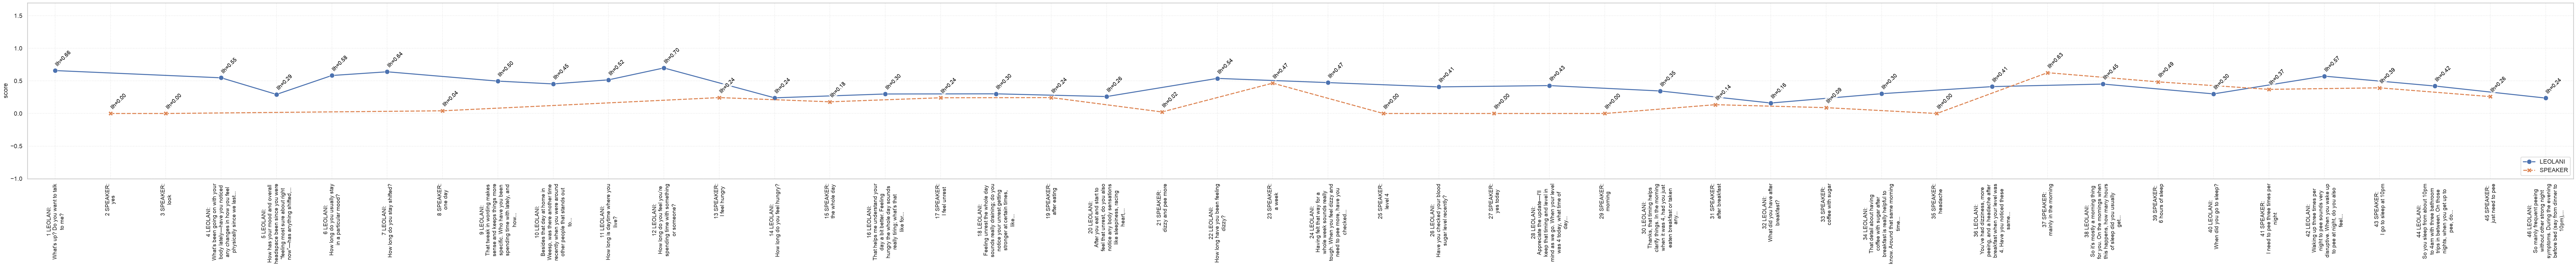

In [14]:
CSV_FILE = os.path.join(evaluation_folder, SCENARIO + "_likelihood_evaluation.csv")
SCORE = "llh"
LABEL = None

settings = plot.PlotSettings()
settings._START = 0
settings._END = -1

plot_file = plot.create_timeline_image_from_csv(CSV_FILE, SCORE, settings,
                                                emissor_path=EMISSOR,
                                                scenario=SCENARIO,
                                                label_column=LABEL)

## Plotting the LLM-as-a-judge coherence scores

Nr of turns 46
Saved plot to /Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480/evaluation/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_llm_judge_llama_cpp_evaluation_llm_coherence_plot.png



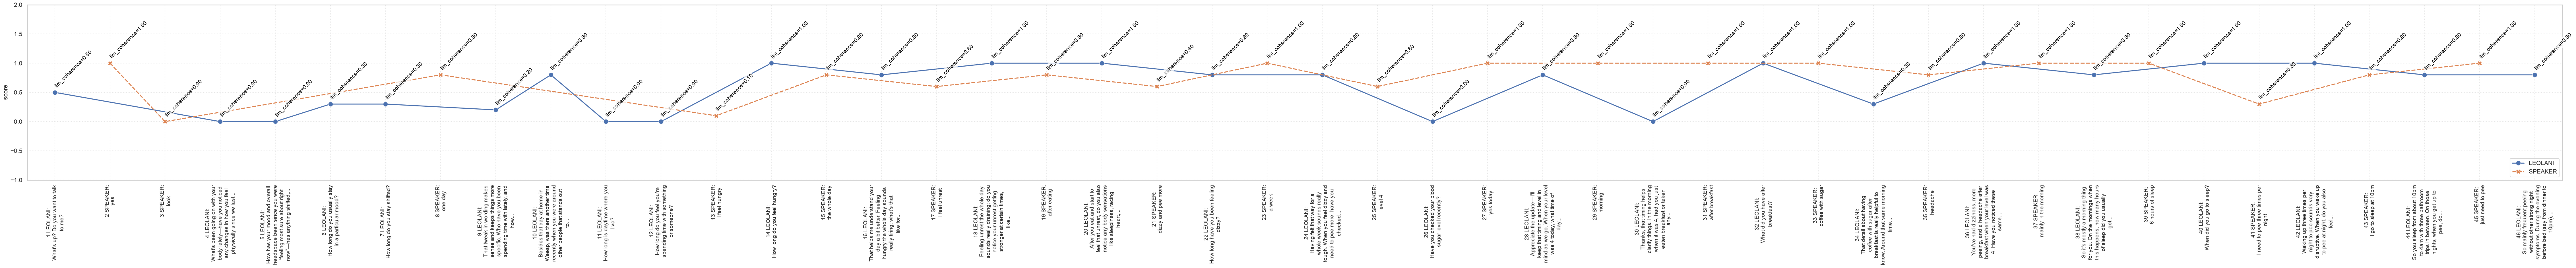

In [15]:
CSV_FILE = os.path.join(evaluation_folder, SCENARIO + "_llm_judge_llama_cpp_evaluation.csv")
SCORE = "llm_coherence"
LABEL = None

settings = plot.PlotSettings()
settings._START = 0
settings._END = -1

plot_file = plot.create_timeline_image_from_csv(CSV_FILE, SCORE, settings,
                                                emissor_path=EMISSOR,
                                                scenario=SCENARIO,
                                                label_column=LABEL)

Nr of turns 46
Saved plot to /Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480/evaluation/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_dialogue_act_evaluation_da_score_plot.png



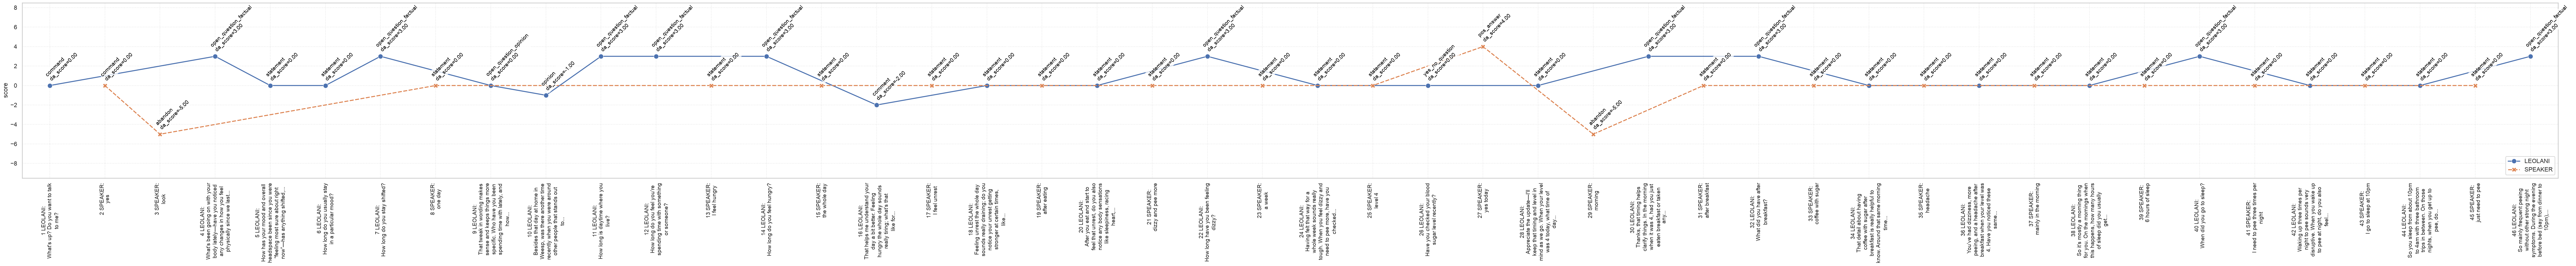

In [16]:
CSV_FILE = os.path.join(evaluation_folder, SCENARIO + "_dialogue_act_evaluation.csv")
SCORE = "da_score"
LABEL = "dialogue_act"

settings = plot.PlotSettings()
settings._START = 0
settings._END = -1

plot_file = plot.create_timeline_image_from_csv(CSV_FILE, SCORE, settings,
                                                emissor_path=EMISSOR,
                                                scenario=SCENARIO,
                                                label_column=LABEL)

Nr of turns 46
Saved plot to /Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480/evaluation/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_emotion_evaluation_emotion_score_plot.png



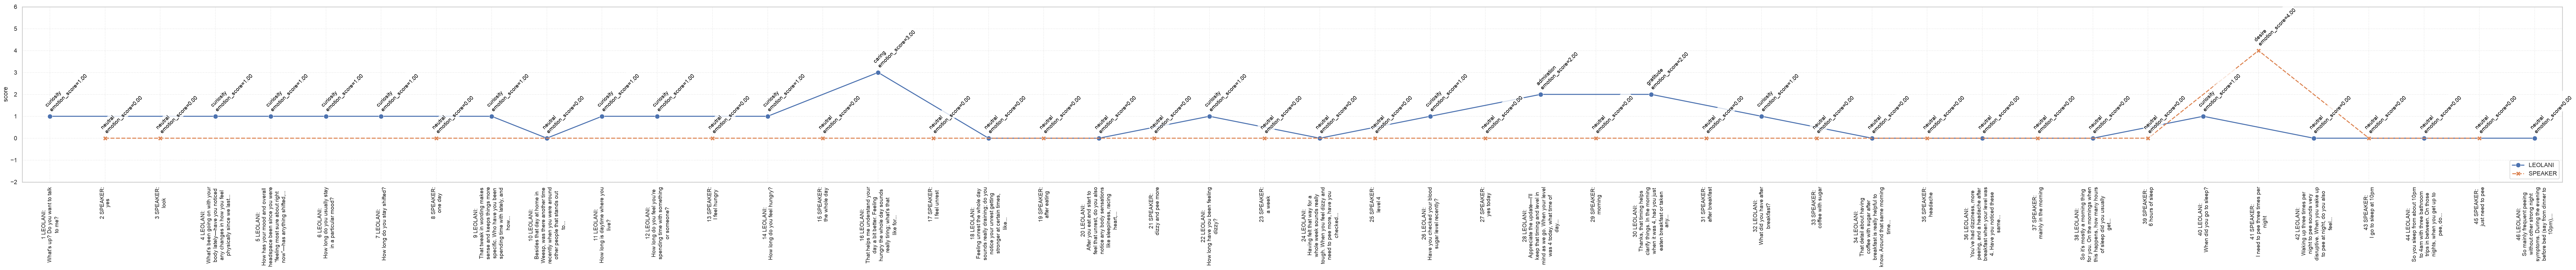

In [17]:
CSV_FILE = os.path.join(evaluation_folder, SCENARIO + "_emotion_evaluation.csv")
SCORE = "emotion_score"
LABEL = "go_emotion"

settings = plot.PlotSettings()
settings._START = 0
settings._END = -1

plot_file = plot.create_timeline_image_from_csv(CSV_FILE, SCORE, settings,
                                                emissor_path=EMISSOR,
                                                scenario=SCENARIO,
                                                label_column=LABEL)

## Plotting all CSV files of a scenario under each other

The function ```create_stacked_timeline_image_from_csvs``` plots all CSV files in the ```evaluation``` folder of the scenario as aligned plots under each other in a single image, so that the scores of the different evaluations can be compared turn by turn.

- ```METRICS```: optional list of substrings to select the CSV files, e.g. ```["likelihood", "llm_judge"]```. With ```None``` all CSV files are plotted.
- ```SCORES```: optional dictionary from a substring of the filename to the score column to plot, e.g. ```{"manual": "Coherent"}```. By default ```llh``` is plotted for the likelihood files, ```llm_coherence``` for the LLM-as-a-judge files and the first score column for other files.

Files that are empty or have no ```Turn```, ```Speaker``` and ```Response``` columns or no scores are skipped. The image is saved in the ```evaluation``` folder as ```<scenario>_stacked_plot.png```.

Nr of turns 46
Nr of turns 46
Nr of turns 46
Nr of turns 46
Saved plot to /Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480/evaluation/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_stacked_plot.png



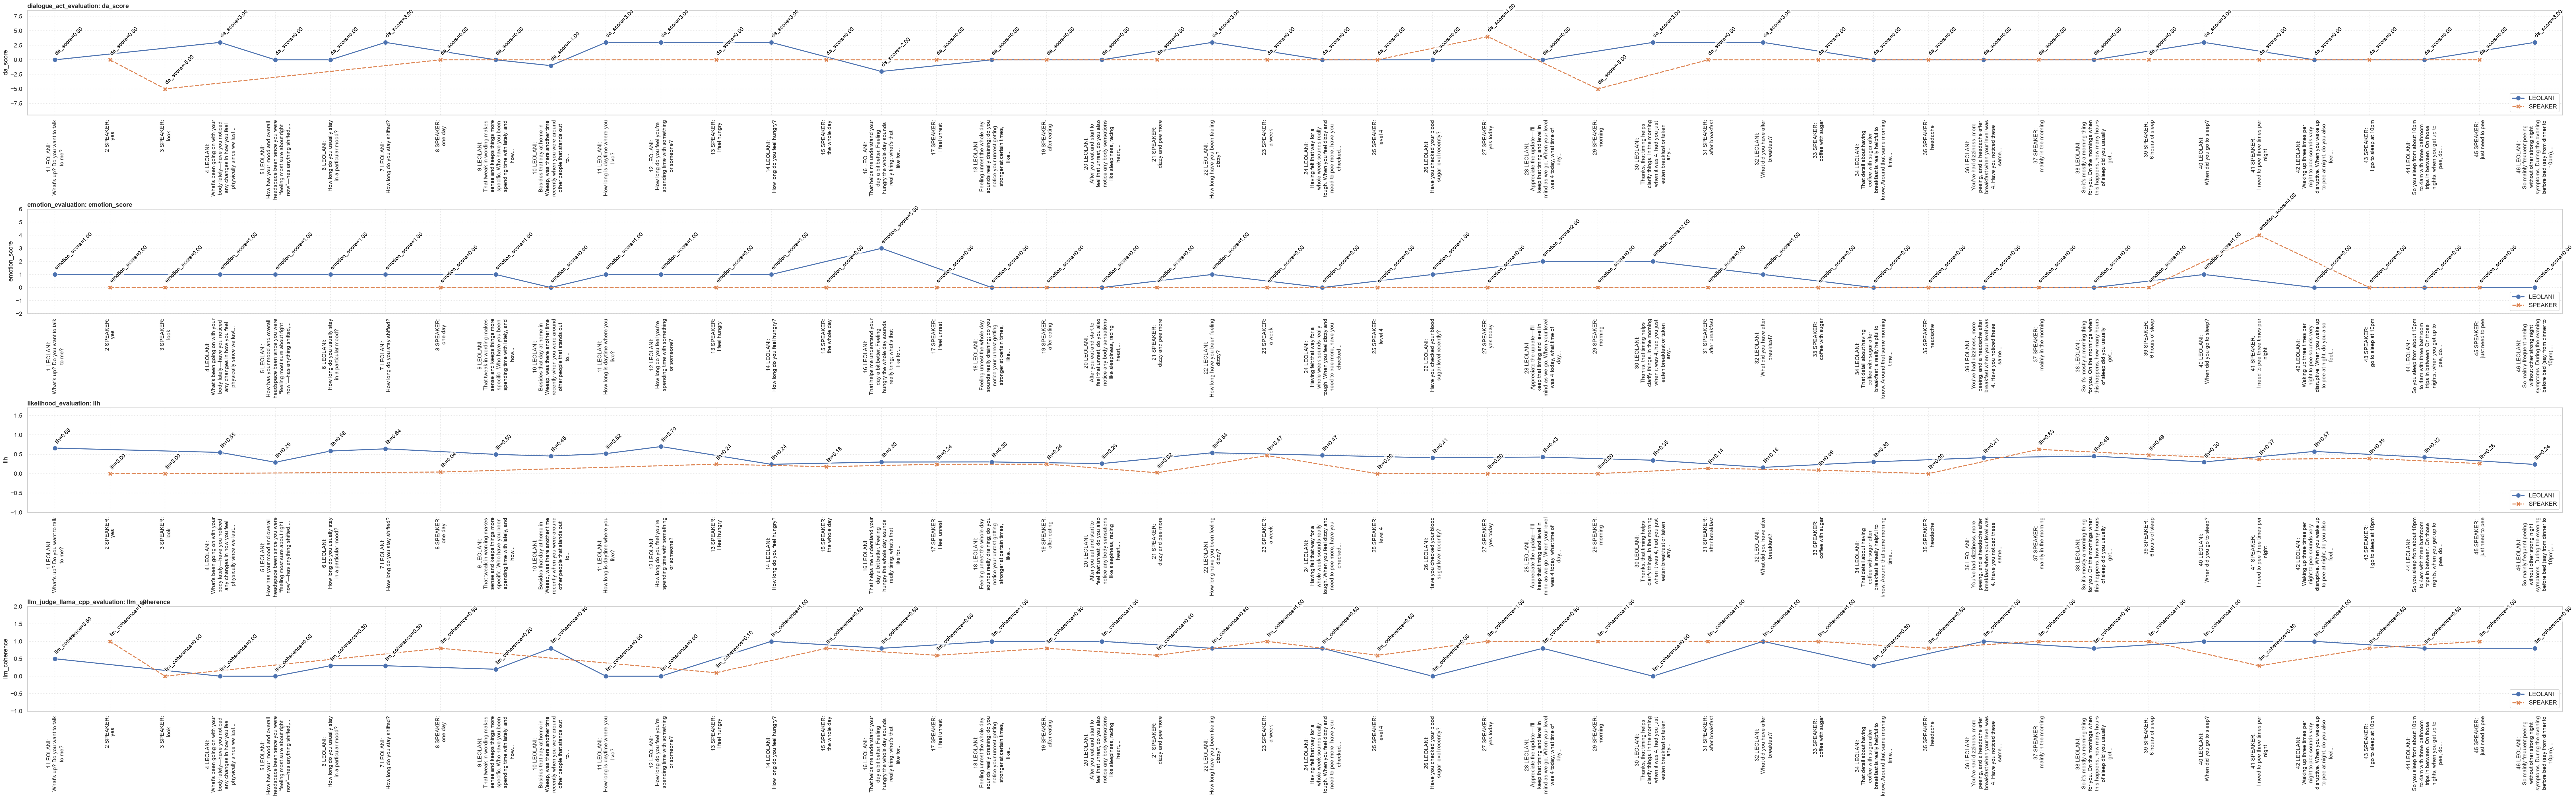

In [18]:
METRICS = None
SCORES = None

settings = plot.PlotSettings()
settings._START = 0
settings._END = -1

plot_file = plot.create_stacked_timeline_image_from_csvs(EMISSOR, SCENARIO, settings,
                                                         metrics=METRICS,
                                                         scores=SCORES)

## Combining all evaluations in a single plot

The stacked plot gives each evaluation its own plot. The next function plots the scores of all CSV files of the scenario as lines in the same plot, so that the evaluations can be compared turn by turn. Each evaluation score has its own colour and each speaker has its own line style. Since all CSV files share the same turns, the text of the turns is shown on the x-axis.

The scores have different ranges, e.g. ```llh``` from 0 to 1 and ```da_score``` from -5 to +5. With ```SCALE = True```, each score is divided by its largest absolute value, so that all scores fall between -1 and 1 while 0 stays 0. ```METRICS``` and ```SCORES``` work as for the stacked plot, and ```_START``` and ```_END``` select the turns, which is useful for long conversations. The plot is saved as ```<scenario>_combined_plot.png``` in the evaluation folder.

Nr of turns 46
Nr of turns 46
Nr of turns 46
Nr of turns 46
Saved plot to /Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480/evaluation/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_combined_plot.png



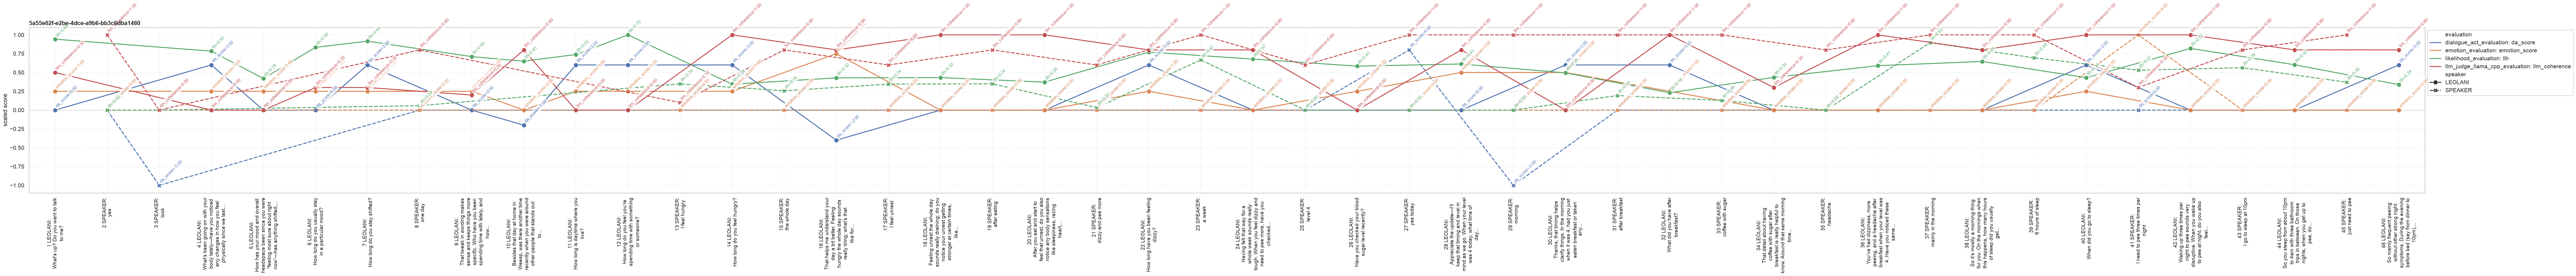

In [19]:
METRICS = None
SCORES = None
SCALE = True

settings = plot.PlotSettings()
settings._START = 0
settings._END = -1

plot_file = plot.create_combined_timeline_image_from_csvs(EMISSOR, SCENARIO, settings,
                                                          metrics=METRICS,
                                                          scores=SCORES,
                                                          scale=SCALE)

## Using other CSV files

Any CSV file with a turn id, a speaker, a text and a score column can be plotted. If the columns have other names, they can be passed with ```turn_column```, ```speaker_column``` and ```text_column```. You also minimally need to specify the column name for the ```scores``` that need to be plotted, e.g.:

```bash
METRICS = None
SCORES = None
SCALE = True

settings = plot.PlotSettings()
settings._START = 0
settings._END = -1
plot.create_timeline_image_from_csv(CSV_FILE, scores=SCORES, settings,
                                    turn_column="id", speaker_column="role", text_column="utterance")
```

## End of notebook